This notebook is a replication of the Statistical Analysis tutorial on keypoint Moseq. Specifically found in the
*[kpms docs](https://keypoint-moseq.readthedocs.io/en/latest/modeling.html#visualization)*

In [1]:
import sys
from pathlib import Path

start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()

# Find the repo dir named 'syllable_generation'
for p in (start, *start.parents):
    if p.name == "syllable_generation":
        REPO_ROOT = p
        break
else:
    raise RuntimeError("Could not find 'syllable_generation'")

# Make the package importable: add the *parent* of the repo to sys.path
PKG_PARENT = REPO_ROOT.parent
for pth in (str(PKG_PARENT), str(REPO_ROOT)):  # both, for convenience
    if pth not in sys.path:
        sys.path.insert(0, pth)

# optional sanity check:
import importlib; importlib.import_module("syllable_generation")

<module 'syllable_generation' from '/home/fsp585/Desktop/FiberphotometryCode/syllable_generation/__init__.py'>

In [2]:
# --- user-editable constants ---
PATH_PREFIX = "/home/fsp585/Desktop/FiberphotometryCode/syllable_generation/"
SESSIONS_PKL = PATH_PREFIX + "loaders/jonathan_ifdn_sessions_w_sylls_full.pkl"
PROJECT_DIR = "/home/fsp585/Desktop/FiberphotometryCode/syllable_generation/syllabizers/keypoint_moseq_syll/demo_project"
MODEL_NAME = "full-run"

USE_CPU = True           # set True to avoid reserving GPU for loading KPMS
OVERWRITE_PICKLE = True  # if False and file exists, we won't overwrite
PRINT_SAMPLE = True      # print a couple sample heads for inspection

In [3]:
import pandas as pd
import numpy as np

import os
os.environ["JAX_PLATFORMS"] = "cpu"  # avoid grabbing the GPU for read-only ops

import keypoint_moseq as kpms
from jax_moseq.models.keypoint_slds import estimate_coordinates
from jax_moseq.utils import unbatch
import jax.numpy as jnp

In [4]:
sessions = pd.read_pickle(SESSIONS_PKL)

In [5]:
model, data, metadata, current_iter = kpms.load_checkpoint(PROJECT_DIR, MODEL_NAME)
results = kpms.extract_results(model, metadata, PROJECT_DIR, MODEL_NAME, save_results=False)

config = kpms.load_config(PROJECT_DIR)

In [6]:
Y_est = estimate_coordinates(
    jnp.array(model['states']['x']),
    jnp.array(model['states']['v']),
    jnp.array(model['states']['h']),
    jnp.array(model['params']['Cd'])
    
)

coordinates_est = unbatch(Y_est, *metadata)
config['bodyparts'] = config['use_bodyparts']

In [7]:
kpms.reindex_syllables_in_checkpoint(PROJECT_DIR, MODEL_NAME);

Reindexing: 100%|███████████| 30/30 [00:29<00:00,  1.00model snapshot/s]


Saving trajectory plots to /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/syllabizers/keypoint_moseq_syll/demo_project/full-run/trajectory_plots


Generating trajectory plots: 100%|██████| 49/49 [00:14<00:00,  3.44it/s]


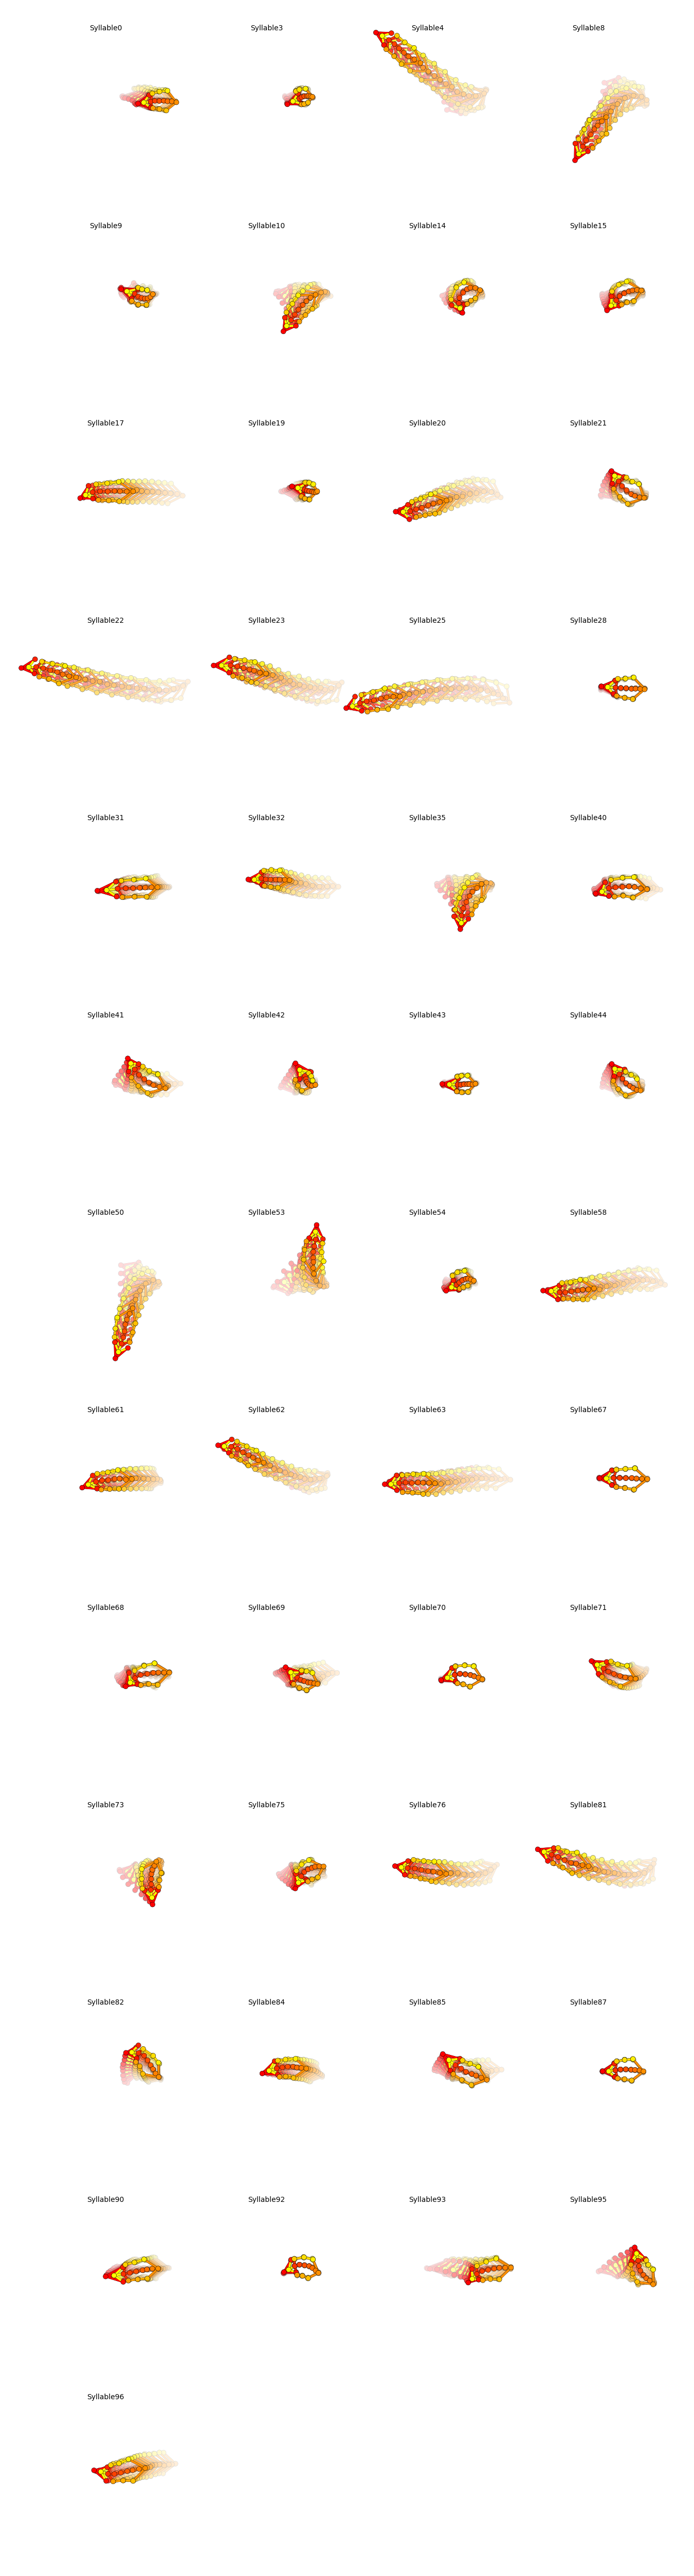

In [8]:
kpms.generate_trajectory_plots(coordinates_est, results, PROJECT_DIR, MODEL_NAME, **config)

In [9]:
npz_path = Path(PROJECT_DIR) / MODEL_NAME / "video_frame_indexes.npz"
video_frame_indexes = dict(np.load(npz_path, allow_pickle=False))

In [10]:
kpms.generate_grid_movies(results, PROJECT_DIR, MODEL_NAME, coordinates=coordinates_est, 
                          video_frame_indexes=video_frame_indexes,
                          overlay_keypoints=False, **config);

Writing grid movies to /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/syllabizers/keypoint_moseq_syll/demo_project/full-run/grid_movies
Using window size of 240 pixels


Generating grid movies:   0%|                    | 0/49 [00:00<?, ?it/s]/home/fsp585/miniforge3/envs/kpms/lib/python3.10/subprocess.py:1796: RuntimeWarning:

os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.

Generating grid movies: 100%|███████████| 49/49 [02:56<00:00,  3.60s/it]


Saving dendrogram plot to /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/syllabizers/keypoint_moseq_syll/demo_project/full-run/similarity_dendrogram


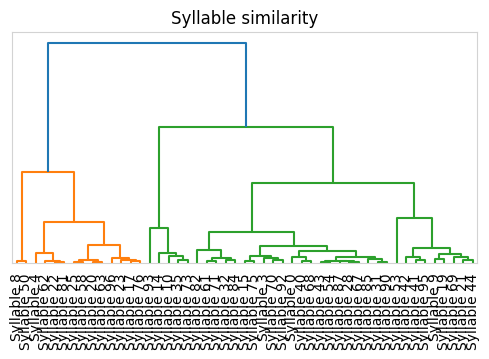

In [11]:
kpms.plot_similarity_dendrogram(coordinates_est, results, PROJECT_DIR, MODEL_NAME, **config)